# 02 · Spreads: what the market charges vs. what the rating says

**The question.** For each bond, how much extra yield over a US Treasury does the market demand? Is that more or less than other bonds with the same credit rating?

**Short answer** (TRACE last trades, Nov 10, 2026; ICE spreads to Nov 9):
1. **Investment grade is calm; junk is not, and the bottom is worst.** Since Aug 22 the IG average barely moved (81 → 91bp, mid-range for 3 years), while BB widened ~40bp, B ~60bp, and CCC ~270bp (~1,040 → ~1,310bp) (§1, `02_oas_by_rating.png`).
2. **Same rating, very different price** (§3, `02_spread_vs_rating.png`; §4):
   - Apple pays *less* than its rating average.
   - Meta's and Alphabet's long bonds pay more.
   - The Meta SPVs pay ~125–165bp over the A average.
   - SpaceX pays ~140–165bp over the BBB average.
   - CoreWeave's unsecured notes pay ~615–690bp over the single-B average, closer to CCC.
3. **Since each bond was sold, SpaceX has cheapened the most** (§5):
   - SpaceX 2036: ~+110bp more than its rating bucket.
   - Meta 2056: +51bp. Alphabet 2056: +20bp.
   - Beignet (−11bp) and Sopaipilla (−9bp) have tightened slightly, and so has Apple.
4. **Part of the long-bond premium is just length, but not most of it.** After a rough maturity adjustment, Meta 2056 is still ~+120bp and SpaceX still ~+130–155bp over their buckets (§6).
5. **Lined up by maturity, the ladder shows clearly.** At ~5 years: Apple 31bp, Alphabet 69, Meta 93, CoreWeave 1,041. At ~25–30 years: Apple 58bp up to SpaceX 279 (§6C).

**The ladder.** Bonds are ordered from "no AI debt" to "all AI debt":

Bonds are ordered from "no AI debt" to "all AI debt":

| Rung | Issuer | Why it's here |
|---|---|---|
| Control | **Apple** (AA+/Aaa) | Big tech with no AI build-out on borrowed money. No new bonds since May 2025. |
| AI spender, fortress balance sheet | **Alphabet** (AA+/Aa2) | ~$175–185B of 2026 capex; borrowed ~$52B in H1 *and* sold stock. Not a clean control. |
| AI spender, corporate claim | **Meta** (AA-/Aa3) | A claim on Facebook/Instagram cash flows. |
| AI spender, project claim | **Beignet / Sopaipilla** (A+) | A claim on a data center leased to Meta, not on Meta itself. |
| AI-levered conglomerate | **SpaceX** (BBB/Baa1) | Net cash today, burning ~$47B a year. |
| AI pure-play | **CoreWeave** (notes B/B1; issuer B+/Ba3) | The unsecured notes, ranked behind ~$25B of secured debt. |

**How this notebook gets there:**

| § | Question | Chart / table |
|---|---|---|
| 1 | Where are credit spreads overall? | `02_oas_by_rating.png` |
| 2 | How do we turn quotes into comparable spreads? | (method) |
| 3 | How does each bond compare with its rating average? | `02_spread_vs_rating.png` |
| 4 | The same numbers, as a table | (table) |
| 5 | Has each bond cheapened since it was sold, beyond its rating bucket? | (table) |
| 6 | How much of this is just maturity? | (tables) |

**Inputs:** `data/fred/` (cached by 01), `bonds.csv`, `quotes.csv`. Run `01_data_pull.ipynb` first.

**Outputs:** `data/spreads.csv` (used by 03, 05, 07) and the two `charts/02_*.png`.

Style: the shared chart style lives in `common.py`. One accent blue marks "the bond" and gray "the benchmark". Rating buckets use a single blue ramp, lighter for safer and darker for riskier, because ratings are an ordered scale.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
from common import INK, INK2, MUTED, GRID, AXIS, SURFACE, BOND, RAMP, source_note, load, ust, treasury_yield, ytm

CHARTS = Path('charts'); CHARTS.mkdir(exist_ok=True)
OAS = {'BAMLC0A1CAAA': 'AAA', 'BAMLC0A2CAA': 'AA', 'BAMLC0A3CA': 'A', 'BAMLC0A4CBBB': 'BBB',
       'BAMLH0A1HYBB': 'BB', 'BAMLH0A2HYB': 'B', 'BAMLH0A3HYC': 'CCC'}

oas = (pd.concat([load(s) for s in OAS], axis=1, sort=True).rename(columns=OAS) * 100).ffill()  # percent → bp
bonds = pd.read_csv('bonds.csv', parse_dates=['maturity']).set_index('bond_id')
quotes = pd.read_csv('quotes.csv', parse_dates=['as_of'])
pd.options.display.float_format = '{:,.1f}'.format

## 1 · Where are credit spreads overall?

The **OAS** (option-adjusted spread) for a rating bucket is the average extra yield its bonds pay over Treasuries. It's the market's going rate for that much default risk.

Investment grade and high yield get separate panels because they live on different scales. A CCC bond pays more than 10x what an AA bond does, and on one axis the IG lines would flatten into the floor.

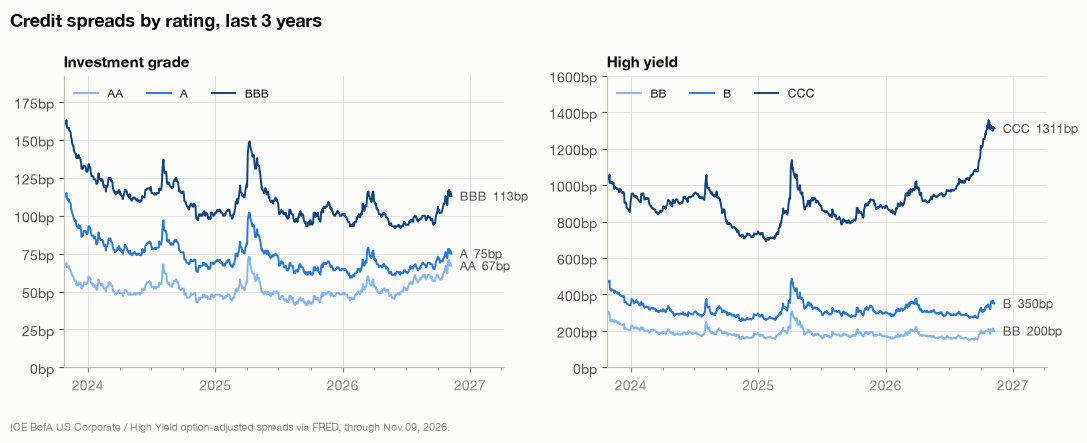

In [2]:
def plot_oas(ax, cols, title):
    for col, color in zip(cols, RAMP):
        s = oas[col].dropna()
        ax.plot(s.index, s, color=color, label=col)
        ax.annotate(f'{col}  {s.iloc[-1]:.0f}bp', (s.index[-1], s.iloc[-1]), xytext=(6, 0),
                    textcoords='offset points', va='center', fontsize=9, color=INK2)
    ax.set_title(title, fontsize=11)
    ax.set_ylim(0, oas[cols].max().max() * 1.18)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.xaxis.set_minor_locator(mdates.MonthLocator((4, 7, 10)))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}bp'))
    ax.legend(loc='upper left', ncols=3, fontsize=8.5)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
plot_oas(a1, ['AA', 'A', 'BBB'], 'Investment grade')
plot_oas(a2, ['BB', 'B', 'CCC'], 'High yield')
for a in (a1, a2):
    a.set_xlim(oas.index.min(), oas.index.max() + pd.Timedelta(days=150))
fig.suptitle('Credit spreads by rating, last 3 years', x=0.01, ha='left', fontweight='bold', fontsize=13)
source_note(fig, f'ICE BofA US Corporate / High Yield option-adjusted spreads via FRED, through {oas.index.max():%b %d, %Y}.')
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(CHARTS / '02_oas_by_rating.png', dpi=200)
plt.show()

**What this shows** (`charts/02_oas_by_rating.png`, above): investment-grade spreads barely moved from Aug 22 to Nov 9 (81 → 91bp, mid-range for the last 3 years; the low was 73bp in January), so investment-grade buyers aren't panicking. Junk is another story. Over the same stretch BB widened ~40bp (158 → 200), B ~60bp (288 → 350), and the **CCC bucket ~270bp (~1,040 → ~1,310bp)**. Junk peaked around Oct 22 (BB 210, CCC 1,340) and has eased a little since. Stress is greatest at the bottom of the junk market, which is where CoreWeave's unsecured notes trade (see below).

**Next:** that's the market's going rate by rating. To compare our bonds with it, every quote has to become a spread measured the same way. §2.

## 2 · How do we turn quotes into comparable spreads?

**Interpolating the Treasury curve.** Treasuries trade at fixed tenors (1, 2, 3, 5, 7, 10, 20, 30 years). A bond with 9.6 years left gets compared with a straight-line blend of the 7- and 10-year yields *on the quote date*. Past 30 years we hold the 30-year flat.

**G-spread** = bond yield − interpolated Treasury yield. It's the simplest "extra yield for credit risk." It ignores call options, which barely matter for these make-whole bonds.

**Price → yield.** Some quotes give only a price (e.g. "83 cents on the dollar"). The yield is the discount rate *y* that makes the bond's remaining cash flows (semiannual coupons plus 100 at maturity) worth today's price:

$$P = \sum_{i=1}^{n} \frac{c/2}{(1+y/2)^{t_i}} + \frac{100}{(1+y/2)^{t_n}}$$

where $t_i$ counts half-years until each payment. We solve for *y* by bisection: guess, check whether the price comes out too high or low, halve the interval, repeat.

Simplifications, with their limits:
- **Bullet bonds only.** Beignet and Sopaipilla amortize (they pay principal down over their lives), so their real average life is ~15 years, not ~22. Here they're treated as bullets, which *understates* their spreads. Notebook 07 §2 models the amortization: ~250–265bp at average life, vs. ~200–240bp here.
- **Accrued interest.** Quoted prices are clean (they exclude interest accrued since the last coupon), so `common.ytm` adds accrued before solving. An earlier version skipped this and overstated Beignet's yield by up to ~25bp.
- **Quotes given as a spread** (term sheets, Bloomberg) are used as published. They're measured against the on-the-run benchmark, which is close to our interpolated curve.

In [3]:
# treasury_yield() and ytm() live in common.py (imported above)

# Check the solver against yields quoted alongside prices by third parties
for bid, px, quoted, as_of in [('CRWV_9.75_2031', 78.0, 16.39, '2026-10-14'), ('META_5.55_2064', 75.80, 7.48, '2026-10-01')]:
    b = bonds.loc[bid]; yrs = (b.maturity - pd.Timestamp(as_of)).days / 365.25
    got = ytm(px, b.coupon, yrs)
    print(f'{bid}: solver {got:.2f}% vs quoted {quoted:.2f}%')
    assert abs(got - quoted) < 0.2

CRWV_9.75_2031: solver 16.39% vs quoted 16.39%
META_5.55_2064: solver 7.48% vs quoted 7.48%


In [4]:
BUCKET = {'AA+': 'AA', 'AA': 'AA', 'AA-': 'AA', 'A+': 'A', 'A': 'A', 'A-': 'A',
          'BBB+': 'BBB', 'BBB': 'BBB', 'BBB-': 'BBB', 'BB+': 'BB', 'BB': 'BB', 'BB-': 'BB',
          'B+': 'B', 'B': 'B', 'B-': 'B'}

def spread_row(q):
    b = bonds.loc[q.bond_id]
    yrs = (b.maturity - q.as_of).days / 365.25
    tsy = treasury_yield(q.as_of, yrs)
    if pd.notna(q.spread_bp):
        g, y, how = q.spread_bp, tsy + q.spread_bp / 100, 'published spread'
    elif pd.notna(q.yield_pct):
        y, how = q.yield_pct, 'published yield'
        g = (y - tsy) * 100
    else:
        y, how = ytm(q.price, b.coupon, yrs), 'yield from price'
        g = (y - tsy) * 100
    bucket = BUCKET[b.rating_sp.split(' ')[0]]
    near = oas[bucket].loc[:q.as_of]
    bucket_oas = near.iloc[-1] if len(near) and (q.as_of - near.index[-1]).days < 7 else np.nan
    return pd.Series({'issuer': b.issuer, 'years': yrs, 'yield': y, 'tsy': tsy, 'g_spread': g, 'how': how,
                      'bucket': bucket, 'bucket_oas': bucket_oas, 'excess': g - bucket_oas})

spreads = pd.concat([quotes, quotes.apply(spread_row, axis=1)], axis=1)
spreads.to_csv('data/spreads.csv', index=False)  # read by 03_implied_default
spreads[['as_of', 'bond_id', 'kind', 'price', 'yield', 'tsy', 'g_spread', 'how', 'bucket', 'bucket_oas', 'excess']]

,as_of,bond_id,kind,price,yield,tsy,g_spread,how,bucket,bucket_oas,excess
0,2025-10-16,BEIGNET_6.581_2049,issue,100.0,6.6,4.6,201.4,published yield,A,65.0,136.4
1,2026-02-10,GOOG_4.100_2031,issue,99.7,4.1,3.7,43.0,published spread,AA,49.0,-6.0
2,2026-02-10,GOOG_4.800_2036,issue,99.8,4.8,4.2,63.0,published spread,AA,49.0,14.0
3,2026-02-10,GOOG_5.650_2056,issue,99.7,5.6,4.8,83.0,published spread,AA,49.0,34.0
4,2026-04-30,META_4.55_2031,issue,100.0,4.6,4.0,53.0,published spread,AA,52.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...
62,2026-11-10,GOOG_4.800_2036,trade,93.3,5.7,4.9,88.5,published yield,AA,67.0,21.5
63,2026-11-10,GOOG_5.650_2056,trade,89.3,6.5,5.3,120.8,published yield,AA,67.0,53.8
64,2026-11-10,AAPL_4.20_2030,trade,97.7,4.9,4.6,31.1,published yield,AA,67.0,-35.9
65,2026-11-10,AAPL_4.75_2035,trade,96.9,5.2,4.8,38.8,published yield,AA,67.0,-28.2


**Excess spread** = the bond's G-spread − the average OAS of its rating bucket *on the same date*. Measuring both on the same day removes "the whole market moved," so an at-issue spread from February can sit next to a trade from October.

- Positive: the market charges more than the rating implies. It thinks the bond is riskier than the label.
- Negative: the market is more relaxed than the rating.

Apple's 2053 bond priced in May 2023, before the start of FRED's ICE history (Oct 2023), so it has no bucket comparison.

## 3 · How does each bond compare with its rating average?

For each bond, its most recent observation: a recent trade (filled dot) or, where we don't have one yet, the spread when it was sold (hollow dot). The gray tick is the average spread for its rating bucket on that date. The horizontal gap is the excess spread.

The x-axis is logarithmic, since spreads here run from ~30bp to ~1,000bp. Each gridline step is a multiple, not a fixed amount.

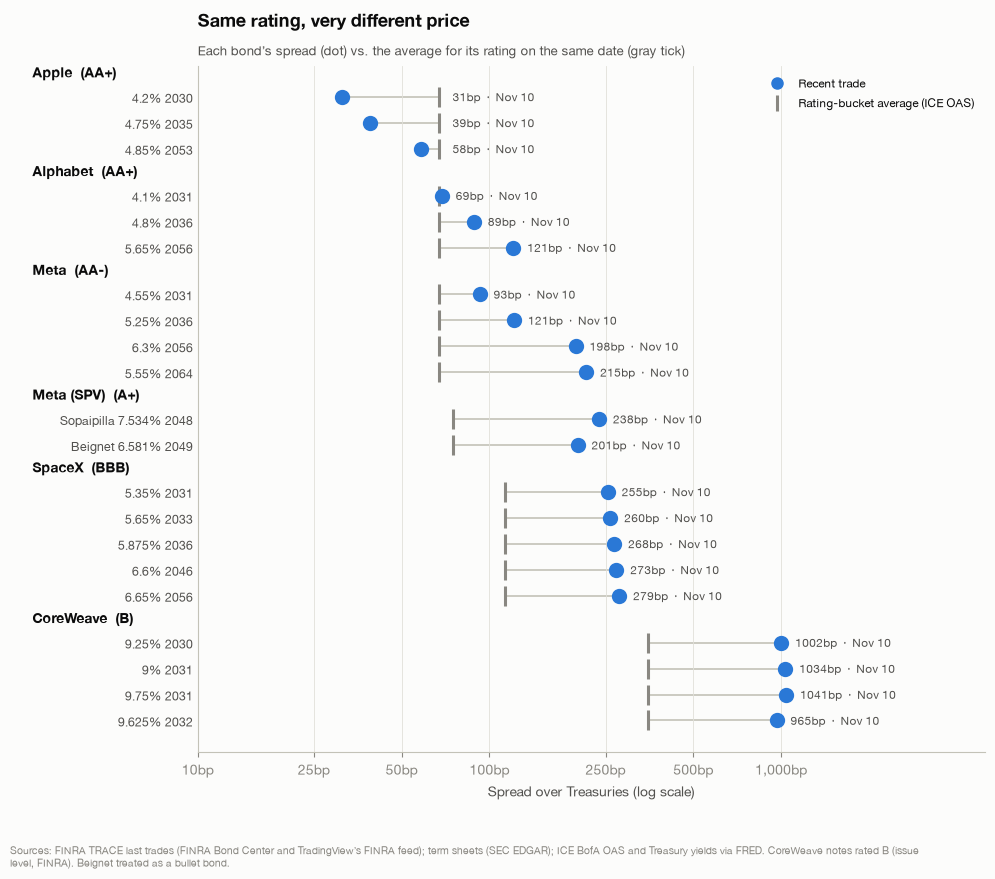

In [5]:
ORDER = ['Apple', 'Alphabet', 'Meta', 'Meta (SPV)', 'SpaceX', 'CoreWeave']
latest = (spreads.sort_values('as_of').groupby('bond_id').tail(1)
          .assign(rank=lambda d: d.issuer.map(ORDER.index), mat=lambda d: d.bond_id.map(bonds.maturity))
          .sort_values(['rank', 'mat']).reset_index(drop=True))

def short_label(bid):
    b = bonds.loc[bid]
    name = {'BEIGNET_6.581_2049': 'Beignet', 'SOPAIPILLA_2048': 'Sopaipilla'}.get(bid, '')
    cpn = f'{b.coupon:g}%' if pd.notna(b.coupon) else ''
    return f'{name} {cpn} {b.maturity:%Y}'.strip()

# y positions with a gap between issuers
ys, y, prev = [], 0, None
for iss in latest.issuer:
    if prev is not None and iss != prev: y += 0.8
    ys.append(y); y += 1; prev = iss
latest['y'] = ys

fig, ax = plt.subplots(figsize=(10, 8.5))
for r in latest.itertuples():
    trade = r.kind == 'trade'
    if pd.notna(r.bucket_oas):
        ax.plot([r.bucket_oas, r.g_spread], [r.y, r.y], color=AXIS, lw=1.2, zorder=1)
        ax.plot(r.bucket_oas, r.y, marker='|', ms=14, mew=2.2, color=MUTED, zorder=2)
    ax.plot(r.g_spread, r.y, 'o', ms=9, mew=2, zorder=3,
            mfc=BOND if trade else SURFACE, mec=BOND)
    when = f'{r.as_of:%b %-d}' if trade else f'at issue, {r.as_of:%b %Y}'
    ax.annotate(f'{r.g_spread:.0f}bp  ·  {when}', (max(r.g_spread, r.bucket_oas if pd.notna(r.bucket_oas) else 0), r.y),
                xytext=(10, 0), textcoords='offset points', va='center', fontsize=8.5, color=INK2)

ax.set_xscale('log')
ax.set_xlim(10, 5000)
ax.xaxis.set_major_locator(mticker.FixedLocator([10, 25, 50, 100, 250, 500, 1000]))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:,.0f}bp'))
ax.xaxis.set_minor_locator(mticker.NullLocator())
ax.set_yticks(latest.y, [short_label(b) for b in latest.bond_id], fontsize=9)
ax.invert_yaxis(); ax.grid(axis='y', visible=False)
ax.tick_params(axis='y', length=0)
for iss, grp in latest.groupby('issuer', sort=False):
    rating = bonds.loc[grp.bond_id.iloc[0], 'rating_sp'].split(' ')[0]
    ax.text(-0.21, grp.y.min() - 0.75, f'{iss}  ({rating})', transform=ax.get_yaxis_transform(),
            fontweight='bold', fontsize=10, color=INK)
ax.set_xlabel('Spread over Treasuries (log scale)')
ax.set_title('Same rating, very different price', pad=28)
ax.text(0, 1.015, 'Each bond’s spread (dot) vs. the average for its rating on the same date (gray tick)',
        transform=ax.transAxes, fontsize=9.5, color=INK2)
# legend: explain the encodings
from matplotlib.lines import Line2D
handles = [Line2D([], [], marker='o', ls='', ms=8, mfc=BOND, mec=BOND, label='Recent trade')]
if (latest.kind == 'issue').any():
    handles.append(Line2D([], [], marker='o', ls='', ms=8, mfc=SURFACE, mec=BOND, mew=2, label='At issue (no recent trade yet)'))
handles.append(Line2D([], [], marker='|', ls='', ms=12, mew=2.2, color=MUTED, label='Rating-bucket average (ICE OAS)'))
ax.legend(handles=handles, loc='upper right', fontsize=8.5)
source_note(fig, 'Sources: FINRA TRACE last trades (FINRA Bond Center and TradingView’s FINRA feed); term sheets (SEC EDGAR);\n'
                 'ICE BofA OAS and Treasury yields via FRED. CoreWeave notes rated B (issue level, FINRA). Beignet treated as a bullet bond.')
fig.tight_layout(rect=(0.02, 0.035, 1, 1))
fig.savefig(CHARTS / '02_spread_vs_rating.png', dpi=200)
plt.show()

**What this shows** (`charts/02_spread_vs_rating.png`, above). Each bond's spread vs. the average for its rating, on the same day:
- **Apple** pays 10–35bp *less* than the AA average: a control with no AI debt, trading as safer than its rating.
- **Alphabet and Meta** pay around the AA average at 5 years, but well above it at 30 years: Meta 2056 is +131bp, Alphabet 2056 +54bp.
- **The Meta SPVs** pay ~125–165bp over the A average, about the same as Meta's own 30-year bond, despite their A+ rating.
- **SpaceX** pays ~140–165bp over the BBB average at every maturity.
- **CoreWeave's unsecured notes** pay ~615–690bp over the single-B average (~965–1,040bp in total), closer to the CCC bucket than to B.

**Next:** the exact numbers are in §4. They raise two questions: is this a recent move (§5), and how much is just maturity (§6)?

## 4 · Excess spread, as a table

The same numbers as the chart. `excess` is in bp over the rating-bucket average. Positive means the market charges more than the rating implies.

In [6]:
tbl = latest[['issuer', 'bond_id', 'as_of', 'kind', 'g_spread', 'bucket', 'bucket_oas', 'excess', 'how']]
tbl

,issuer,bond_id,as_of,kind,g_spread,bucket,bucket_oas,excess,how
0,Apple,AAPL_4.20_2030,2026-11-10,trade,31.1,AA,67.0,-35.9,published yield
1,Apple,AAPL_4.75_2035,2026-11-10,trade,38.8,AA,67.0,-28.2,published yield
2,Apple,AAPL_4.85_2053,2026-11-10,trade,58.3,AA,67.0,-8.7,published yield
3,Alphabet,GOOG_4.100_2031,2026-11-10,trade,68.7,AA,67.0,1.7,published yield
4,Alphabet,GOOG_4.800_2036,2026-11-10,trade,88.5,AA,67.0,21.5,published yield
5,Alphabet,GOOG_5.650_2056,2026-11-10,trade,120.8,AA,67.0,53.8,published yield
6,Meta,META_4.55_2031,2026-11-10,trade,92.6,AA,67.0,25.6,published yield
7,Meta,META_5.25_2036,2026-11-10,trade,121.5,AA,67.0,54.5,published yield
8,Meta,META_6.30_2056,2026-11-10,trade,197.6,AA,67.0,130.6,published yield
9,Meta,META_5.55_2064,2026-11-10,trade,214.8,AA,67.0,147.8,published yield


**What this shows:** the gap grows down the ladder, from Apple (below its bucket) to CoreWeave (+615–690bp). Within each issuer, the excess rises with maturity. That's partly real and partly a measurement problem, because the bucket averages blend all maturities. §6 deals with it.

**Next:** a cleaner comparison is the *same bond* now versus when it was sold, since its maturity barely changes. §5.

## 5 · Has it gotten worse since issue? (bucket-adjusted)

For bonds with both a term-sheet spread and a recent trade: how much did the **excess** spread change? A rising excess means the bond widened *more than its rating bucket did*, i.e. something specific to this issuer or structure, not the overall market.

In [7]:
both = spreads.dropna(subset=['excess'])
first = both[both.kind == 'issue'].groupby('bond_id').head(1).set_index('bond_id')
last = both[both.kind == 'trade'].sort_values('as_of').groupby('bond_id').tail(1).set_index('bond_id')
common = first.index.intersection(last.index)
pd.DataFrame({
    'issued': first.loc[common, 'as_of'].dt.date, 'excess at issue': first.loc[common, 'excess'],
    'latest': last.loc[common, 'as_of'].dt.date, 'excess now': last.loc[common, 'excess'],
    'change (bp)': last.loc[common, 'excess'] - first.loc[common, 'excess'],
})

,issued,excess at issue,latest,excess now,change (bp)
bond_id,,,,,
BEIGNET_6.581_2049,2025-10-16,136.4,2026-11-10,125.7,-10.7
GOOG_4.100_2031,2026-02-10,-6.0,2026-11-10,1.7,7.7
GOOG_4.800_2036,2026-02-10,14.0,2026-11-10,21.5,7.5
GOOG_5.650_2056,2026-02-10,34.0,2026-11-10,53.8,19.8
META_4.55_2031,2026-04-30,1.0,2026-11-10,25.6,24.6
META_5.25_2036,2026-04-30,38.0,2026-11-10,54.5,16.5
META_6.30_2056,2026-04-30,80.0,2026-11-10,130.6,50.6
SPCX_5.875_2036,2026-06-23,47.0,2026-11-10,155.0,108.0
SOPAIPILLA_2048,2026-07-27,172.1,2026-11-10,162.7,-9.4


**What this shows** (change in excess spread, bp, from sale to Nov 10):
- **SpaceX 2036: +108bp.** By far the biggest move. SpaceX's bonds have cheapened sharply relative to BBB since June.
- **Meta 2056: +51bp. Alphabet 2056: +20bp.** The long ends of the AI spenders have cheapened. Their 5- and 10-year bonds have barely moved.
- **Beignet: −11bp.** Slightly tighter against its bucket over a year, despite its price falling ~8 points. That fall was mostly interest rates (05 §5).
- **Sopaipilla: −9bp,** having come cheap in July.
- **Apple: −8 to −20bp,** richer still.

**Next:** that answers "did it get worse?" but not "is it priced high?". The level question needs the maturity problem fixed. §6.

## 6 · The maturity problem (first attempt, documented)

**The problem.** Longer bonds pay more over Treasuries even from the same issuer, because lenders want more for tying money up longer. That's visible in the Nov 9 ICE data: investment-grade bonds maturing in 1–3 years paid ~62bp, while 7+ year bonds paid ~108bp. The rating averages we compare against (e.g. "AA") blend all maturities, roughly 7–10 years on average. So a 30-year bond shows positive excess spread even if nothing is wrong with the issuer, and a 4-year bond looks artificially cheap.

**Approaches considered:**

| | Approach | Status |
|---|---|---|
| A | **Same bond, change since issue.** Maturity barely changes, so the effect cancels. | Done (section 5). Answers "did it get worse?", not "is it priced high?" |
| B | **Scale the rating average by the IG maturity curve:** `benchmark = rating OAS × (IG OAS for this maturity ÷ IG OAS overall)` | Implemented below as a rough fix |
| C | **Line up bonds of similar maturity** across issuers (2030–31, 2033–36, 2049–64) | Implemented below. No model, easy to read |
| D | **Rating × maturity benchmarks.** ICE publishes indices like "A-rated, 7–10y" (not on FRED), or we fit a spread curve per rating from many TRACE prints | Later step. Needs data we don't have yet |

**B's assumption, stated plainly:** every rating's spread curve has the same *shape* as the overall IG curve, just scaled up or down. That's untested. Lower-rated curves are often flatter or even inverted, since a weak company's near-term risk can exceed its long-term risk. FRED has no maturity breakdown for high yield, so **CoreWeave is not adjusted**.

In [8]:
MAT_SERIES = [(3, 'BAMLC1A0C13Y'), (5, 'BAMLC2A0C35Y'), (7, 'BAMLC3A0C57Y'),
              (10, 'BAMLC4A0C710Y'), (15, 'BAMLC7A0C1015Y'), (np.inf, 'BAMLC8A0C15PY')]
mat_oas = pd.concat([load(s) for _, s in MAT_SERIES], axis=1, sort=True).ffill() * 100
ig_all = load('BAMLC0A0CM').ffill() * 100

def maturity_factor(date, years):
    sid = next(s for cap, s in MAT_SERIES if years <= cap)
    return mat_oas[sid].loc[:date].iloc[-1] / ig_all.loc[:date].iloc[-1]

print('IG maturity curve, latest (bp) and factor vs. all-maturity IG:')
last = mat_oas.iloc[-1]
display(pd.DataFrame({'OAS (bp)': last.values, 'factor': (last / ig_all.iloc[-1]).values},
                     index=['1-3y', '3-5y', '5-7y', '7-10y', '10-15y', '15y+']).T.round(2))

def adjust(df):
    ig_bucket = df.bucket.isin(['AAA', 'AA', 'A', 'BBB'])
    f = [maturity_factor(d, y) if ok else np.nan for d, y, ok in zip(df.as_of, df.years, ig_bucket)]
    return df.assign(mat_factor=f, bucket_oas_adj=lambda d: d.bucket_oas * d.mat_factor,
                     excess_adj=lambda d: d.g_spread - d.bucket_oas_adj)

latest_adj = adjust(latest)
latest_adj[['issuer', 'bond_id', 'years', 'g_spread', 'bucket', 'bucket_oas', 'mat_factor', 'bucket_oas_adj', 'excess', 'excess_adj']]

IG maturity curve, latest (bp) and factor vs. all-maturity IG:


,1-3y,3-5y,5-7y,7-10y,10-15y,15y+
OAS (bp),62.0,81.0,95.0,109.0,108.0,108.0
factor,0.7,0.9,1.0,1.2,1.2,1.2


,issuer,bond_id,years,g_spread,bucket,bucket_oas,mat_factor,bucket_oas_adj,excess,excess_adj
0,Apple,AAPL_4.20_2030,3.5,31.1,AA,67.0,0.9,59.6,-35.9,-28.5
1,Apple,AAPL_4.75_2035,8.5,38.8,AA,67.0,1.2,80.3,-28.2,-41.4
2,Apple,AAPL_4.85_2053,26.5,58.3,AA,67.0,1.2,79.5,-8.7,-21.3
3,Alphabet,GOOG_4.100_2031,4.3,68.7,AA,67.0,0.9,59.6,1.7,9.0
4,Alphabet,GOOG_4.800_2036,9.3,88.5,AA,67.0,1.2,80.3,21.5,8.3
5,Alphabet,GOOG_5.650_2056,29.3,120.8,AA,67.0,1.2,79.5,53.8,41.3
6,Meta,META_4.55_2031,4.5,92.6,AA,67.0,0.9,59.6,25.6,33.0
7,Meta,META_5.25_2036,9.5,121.5,AA,67.0,1.2,80.3,54.5,41.2
8,Meta,META_6.30_2056,29.5,197.6,AA,67.0,1.2,79.5,130.6,118.1
9,Meta,META_5.55_2064,37.8,214.8,AA,67.0,1.2,79.5,147.8,135.3


**What this shows:** `excess` is the original measure and `excess_adj` is after the maturity scaling. Long bonds lose some excess and short bonds gain some.

Change since issue with the adjustment applied. This should barely differ from section 5, since each bond's maturity changes little. If it does differ, the IG curve's shape changed between the two dates.

In [9]:
both_adj = adjust(spreads.dropna(subset=['excess']).assign(issuer=lambda d: d.bond_id.map(bonds.issuer)))
f = both_adj[both_adj.kind == 'issue'].groupby('bond_id').head(1).set_index('bond_id')
l = both_adj[both_adj.kind == 'trade'].sort_values('as_of').groupby('bond_id').tail(1).set_index('bond_id')
c = f.index.intersection(l.index)
pd.DataFrame({'change, raw (bp)': l.loc[c, 'excess'] - f.loc[c, 'excess'],
              'change, maturity-adjusted (bp)': l.loc[c, 'excess_adj'] - f.loc[c, 'excess_adj']})

,"change, raw (bp)","change, maturity-adjusted (bp)"
bond_id,,
BEIGNET_6.581_2049,-10.7,-11.7
GOOG_4.100_2031,7.7,17.0
GOOG_4.800_2036,7.5,5.1
GOOG_5.650_2056,19.8,20.0
META_4.55_2031,24.6,32.6
META_5.25_2036,16.5,10.9
META_6.30_2056,50.6,49.0
SPCX_5.875_2036,108.0,107.0
SOPAIPILLA_2048,-9.4,-4.4


### C · Bonds of similar maturity, side by side

The simplest fix that needs no assumptions: compare bonds that mature around the same time. Within each group the maturity effect is roughly equal, so differences in spread are mostly about the issuer and the structure. The groups aren't perfectly matched (e.g. Apple 2053 vs. SpaceX 2056), so read small gaps loosely.

In [10]:
GROUPS = {'~5 years (2030–31)': ['AAPL_4.20_2030', 'GOOG_4.100_2031', 'META_4.55_2031', 'CRWV_9.75_2031'],
          '~10 years (2033–36)': ['AAPL_4.75_2035', 'GOOG_4.800_2036', 'META_5.25_2036', 'SPCX_5.650_2033', 'SPCX_5.875_2036'],
          '~25–30 years (2048–56)': ['AAPL_4.85_2053', 'GOOG_5.650_2056', 'META_6.30_2056', 'BEIGNET_6.581_2049',
                                     'SOPAIPILLA_2048', 'SPCX_6.650_2056']}
lat = latest.set_index('bond_id')
rows = [(g, b, lat.loc[b, 'as_of'].date(), lat.loc[b, 'kind'], round(lat.loc[b, 'years'], 1), lat.loc[b, 'g_spread'])
        for g, ids in GROUPS.items() for b in ids if b in lat.index]
pd.DataFrame(rows, columns=['maturity group', 'bond', 'as of', 'kind', 'years left', 'spread (bp)']).set_index(['maturity group', 'bond'])

as of   kind  years left  \
maturity group         bond                                                
~5 years (2030–31)     AAPL_4.20_2030      2026-11-10  trade         3.5   
                       GOOG_4.100_2031     2026-11-10  trade         4.3   
                       META_4.55_2031      2026-11-10  trade         4.5   
                       CRWV_9.75_2031      2026-11-10  trade         4.9   
~10 years (2033–36)    AAPL_4.75_2035      2026-11-10  trade         8.5   
                       GOOG_4.800_2036     2026-11-10  trade         9.3   
                       META_5.25_2036      2026-11-10  trade         9.5   
                       SPCX_5.650_2033     2026-11-10  trade         6.7   
                       SPCX_5.875_2036     2026-11-10  trade         9.7   
~25–30 years (2048–56) AAPL_4.85_2053      2026-11-10  trade        26.5   
                       GOOG_5.650_2056     2026-11-10  trade        29.3   
                       META_6.30_2056      2026-11-10  trade        29.5   
                       BEIGNET_6.581_2049  2026-11-10  trade        22.6   
                       SOPAIPILLA_2048     2026-11-10  trade        22.1   
                       SPCX_6.650_2056     2026-11-10  trade        29.7   

                                           spread (bp)  
maturity group         bond                             
~5 years (2030–31)     AAPL_4.20_2030             31.1  
                       GOOG_4.100_2031            68.7  
                       META_4.55_2031             92.6  
                       CRWV_9.75_2031          1,041.3  
~10 years (2033–36)    AAPL_4.75_2035             38.8  
                       GOOG_4.800_2036            88.5  
                       META_5.25_2036            121.5  
                       SPCX_5.650_2033           259.9  
                       SPCX_5.875_2036           268.0  
~25–30 years (2048–56) AAPL_4.85_2053             58.3  
                       GOOG_5.650_2056           120.8  
                       META_6.30_2056            197.6  
                       BEIGNET_6.581_2049        200.7  
                       SOPAIPILLA_2048           237.7  
                       SPCX_6.650_2056           278.7

**What this shows:** bonds of similar maturity, side by side (spread in bp):
- **~5 years:** Apple 31, Alphabet 69, Meta 93, CoreWeave 1,041.
- **~10 years:** Apple 39, Alphabet 89, Meta 122, SpaceX 260–268.
- **~25–30 years:** Apple 58, Alphabet 121, Meta 198, Beignet 201, Sopaipilla 238, SpaceX 279.

The ladder holds at every maturity. The SPVs sit at or above Meta's own 30-year bond. 07 §3 measures that gap properly, at matched average life: ~110–125bp.

## Findings, by section

**§1 · Investment grade is calm; junk is widening, worst at the bottom.** From Aug 22 to Nov 9, IG went 81 → 91bp (mid-range for 3 years), BB +~40bp, B +~60bp, CCC ~1,040 → ~1,310bp. (`02_oas_by_rating.png`)

**§3–4 · Same rating, different price, and the gap tracks how much AI debt sits behind the bond.** (`02_spread_vs_rating.png`)
- Apple trades through its AA average.
- Meta's long bonds are ~+130–150bp over AA.
- The SPVs are ~+125–165bp over A.
- SpaceX is ~+140–165bp over BBB.
- CoreWeave's unsecured notes are ~+615–690bp over B, near CCC.

**§5 · Since issue, SpaceX has cheapened most** (+108bp vs. its bucket), then the long ends of Meta (+51bp) and Alphabet (+20bp). Beignet (−11bp) and Sopaipilla (−9bp) have tightened slightly against their bucket. This change is the robust number, because comparing the same bond cancels maturity.

**§6 · Maturity explains some of the long-bond premium, not most of it.** After the rough adjustment, Meta 2056 is still ~+120bp and SpaceX ~+130–155bp. Lined up by maturity, the ladder holds at 5, 10 and 30 years.

**Handoff:** `data/spreads.csv`. 03 turns these spreads into implied default odds; 05 compares them with the stock; 07 re-measures the SPVs as amortizing bonds.

## Notes and gaps

- **Where prices come from.** Every bond now has a Nov 10 TRACE last trade, read from its FINRA bond page (earlier dates came from FINRA's Bond Center and TradingView's FINRA feed). FINRA shows no yield for the SpaceX 2033–2056 notes and Beignet; for SpaceX we compute it from the price. Each bond's FINRA symbol is in `bonds.csv` → `finra_symbol`; the page is `finra.org/finra-data/fixed-income/bond?symbol=<symbol>&bondType=CORP`. A *last trade* is one print, not a closing price, so a single odd-lot trade can be off by a point or so. Treat these levels as approximate.
- **Use like-for-like benchmarks.** Press spreads are often quoted against the 10-year Treasury no matter how long the bond is (Sopaipilla's "287.5bp" was), so they can't be compared with our curve-matched spreads. Where a source gives a yield, we recompute the spread ourselves.
- **Treasury curve lag.** FRED usually posts Treasury yields a business day late, so Nov 10 bond yields are currently compared with the Nov 9 curve. Re-run after a FRED refresh.
- **The robust number is the change since issue** (see section 6 for the maturity fix attempts). The rating-bucket averages blend all maturities (roughly 7–10 years on average), so long bonds show some positive excess just for being long. Comparing the *same bond* at issue vs. now cancels that out. That's the table in section 5, and it's the one to quote in the post.
- **CoreWeave's unsecured notes** are compared with the single-B bucket because the notes are rated B (S&P issue rating per FINRA, Oct 20 2026; the issuer is B+). Their spread sits closer to the CCC average.
- **Meta 2064** (Benzinga, early Oct, ~187bp) looked suspect before we had TRACE data. It now fits: Meta's 2056 trades at ~200bp and its 2064 at ~215bp.
- **Beignet and Sopaipilla** amortize, and Beignet pays quarterly. Here both are treated as semiannual bullets, so their spreads are understated. 07 §2 has the amortizing version.